In [3]:
pip install pandas openpyxl

In [4]:
import pandas as pd

df = pd.read_excel(
    "/content/Manufacturering_analysis/manufacturing_process_analysis_practice_data.xlsx",
    sheet_name="Process_Data"
)

print(df.head())
print(df.shape)
print(df.columns.tolist())

        Date    Line      Machine    Product Shift  Planned_Units  \
0 2026-07-01  Line 1       CNC-02    Mount-C     A            585   
1 2026-07-01  Line 1  Assembly-01  Bracket-B     A            588   
2 2026-07-01  Line 1  Assembly-01  Bracket-B     B            460   
3 2026-07-01  Line 1  Assembly-01  Bracket-B     C            421   
4 2026-07-01  Line 2       CNC-02  Bracket-B     B            539   

   Actual_Units  Cycle_Time_sec_per_unit  Downtime_min  Scrap_Units  \
0           542                     27.9          41.5           16   
1           536                     26.8          27.1           26   
2           386                     25.3          53.7           14   
3           387                     33.3          39.0            6   
4           450                     25.3          57.8           32   

   Good_Units  Operators  Material_Wait_min  Changeover_min  Scrap_Rate_pct  \
0         569          5               22.2            18.8            2.74   


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Data types:")
print(df.dtypes)

Missing values:
Date                         0
Line                         0
Machine                      0
Product                      0
Shift                        0
Planned_Units                0
Actual_Units                 0
Cycle_Time_sec_per_unit      0
Downtime_min                 0
Scrap_Units                  0
Good_Units                   0
Operators                    0
Material_Wait_min            0
Changeover_min               0
Scrap_Rate_pct               0
Output_Achievement_pct       0
Availability_proxy_pct       0
Throughput_units_per_hour    0
Delay_Flag                   0
dtype: int64
Duplicate rows: 0
Data types:
Date                         datetime64[ns]
Line                                 object
Machine                              object
Product                              object
Shift                                object
Planned_Units                         int64
Actual_Units                          int64
Cycle_Time_sec_per_unit             float64


In [6]:
print(df.describe().round(2).T)

                           count                 mean                  min  \
Date                         180  2026-07-15 00:56:00  2026-07-01 00:00:00   
Planned_Units              180.0               504.95                420.0   
Actual_Units               180.0               452.87                349.0   
Cycle_Time_sec_per_unit    180.0                29.04                 17.6   
Downtime_min               180.0                38.44                  4.0   
Scrap_Units                180.0                18.94                  1.0   
Good_Units                 180.0               486.01                397.0   
Operators                  180.0                  6.0                  4.0   
Material_Wait_min          180.0                15.02                  0.0   
Changeover_min             180.0                19.77                  8.1   
Scrap_Rate_pct             180.0                 3.75                 0.21   
Output_Achievement_pct     180.0                89.62           

In [7]:
print("Total planned units:", df["Planned_Units"].sum())
print("Total actual units:", df["Actual_Units"].sum())

print("Average cycle time:",
      round(df["Cycle_Time_sec_per_unit"].mean(), 2), "seconds")

print("Total downtime:",
      round(df["Downtime_min"].sum(), 2), "minutes")

print("Overall scrap rate:",
      round(df["Scrap_Units"].sum() /
            df["Planned_Units"].sum() * 100, 2), "%")

print("Average material waiting time:",
      round(df["Material_Wait_min"].mean(), 2), "minutes")

Total planned units: 90891
Total actual units: 81517
Average cycle time: 29.04 seconds
Total downtime: 6918.5 minutes
Overall scrap rate: 3.75 %
Average material waiting time: 15.02 minutes


In [8]:
line_summary = df.groupby("Line").agg(
    Planned_Units=("Planned_Units", "sum"),
    Actual_Units=("Actual_Units", "sum"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Total_Downtime=("Downtime_min", "sum"),
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Scrap_Units=("Scrap_Units", "sum")
)

line_summary["Output_Achievement_pct"] = (
    line_summary["Actual_Units"] /
    line_summary["Planned_Units"] * 100
).round(2)

line_summary["Scrap_Rate_pct"] = (
    line_summary["Scrap_Units"] /
    line_summary["Planned_Units"] * 100
).round(2)

print(line_summary.round(2))

        Planned_Units  Actual_Units  Avg_Cycle_Time  Total_Downtime  \
Line                                                                  
Line 1          38402         34812           28.30          2634.5   
Line 2          29324         26106           28.67          2395.1   
Line 3          23165         20599           30.77          1888.9   

        Avg_Material_Wait  Scrap_Units  Output_Achievement_pct  Scrap_Rate_pct  
Line                                                                            
Line 1              12.59         1295                   90.65            3.37  
Line 2              15.72         1138                   89.03            3.88  
Line 3              18.28          977                   88.92            4.22  


In [9]:
shift_summary = df[df["Line"] == "Line 3"].groupby("Shift").agg(
    Actual_Units=("Actual_Units", "sum"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Total_Downtime=("Downtime_min", "sum"),
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Scrap_Units=("Scrap_Units", "sum")
)

print(shift_summary.round(2))

       Actual_Units  Avg_Cycle_Time  Total_Downtime  Avg_Material_Wait  \
Shift                                                                    
A              7574           28.72           607.7              18.67   
B              6848           31.73           631.8              19.71   
C              6177           32.10           649.4              16.32   

       Scrap_Units  
Shift               
A              356  
B              356  
C              265  


In [10]:
pivot = df.pivot_table(
    index="Line",
    columns="Shift",
    values="Downtime_min",
    aggfunc="mean"
)

print("Average Downtime by Line and Shift:")
print(pivot.round(2))

pivot_wait = df.pivot_table(
    index="Line",
    columns="Shift",
    values="Material_Wait_min",
    aggfunc="mean"
)

print("\nAverage Material Waiting Time:")
print(pivot_wait.round(2))

Average Downtime by Line and Shift:
Shift       A      B      C
Line                       
Line 1  31.96  34.40  37.22
Line 2  32.09  44.49  46.72
Line 3  37.98  42.12  46.39

Average Material Waiting Time:
Shift       A      B      C
Line                       
Line 1  11.26  12.55  14.60
Line 2  16.54  15.90  14.62
Line 3  18.67  19.71  16.32


In [11]:
correlation = df["Material_Wait_min"].corr(df["Downtime_min"])
print("Correlation:", round(correlation, 3))

Correlation: -0.057


In [12]:
correlation = df["Cycle_Time_sec_per_unit"].corr(
    df["Output_Achievement_pct"]
)

print("Cycle Time vs Output Achievement:", round(correlation, 3))

Cycle Time vs Output Achievement: -0.042


In [13]:
product_summary = df.groupby("Product").agg(
    Planned_Units=("Planned_Units", "sum"),
    Actual_Units=("Actual_Units", "sum"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Downtime=("Downtime_min", "mean"),
    Scrap_Units=("Scrap_Units", "sum")
)

product_summary["Output_Achievement_pct"] = (
    product_summary["Actual_Units"] /
    product_summary["Planned_Units"] * 100
).round(2)

print(product_summary.round(2))

           Planned_Units  Actual_Units  Avg_Cycle_Time  Avg_Downtime  \
Product                                                                
Bracket-A          40145         35936           27.14         38.20   
Bracket-B          32130         28885           29.88         38.34   
Mount-C            18616         16696           31.62         39.11   

           Scrap_Units  Output_Achievement_pct  
Product                                         
Bracket-A         1628                   89.52  
Bracket-B         1137                   89.90  
Mount-C            645                   89.69  


In [14]:
product_summary["Scrap_Rate_pct"] = (
    product_summary["Scrap_Units"] /
    product_summary["Planned_Units"] * 100
).round(2)

print(product_summary[["Scrap_Rate_pct", "Output_Achievement_pct"]])

           Scrap_Rate_pct  Output_Achievement_pct
Product                                          
Bracket-A            4.06                   89.52
Bracket-B            3.54                   89.90
Mount-C              3.46                   89.69


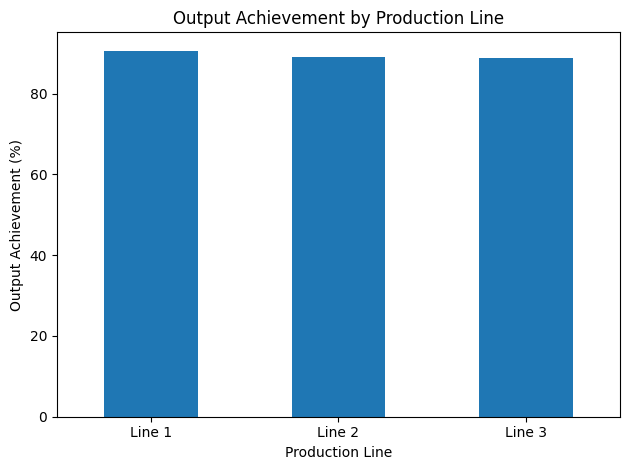

In [15]:
import matplotlib.pyplot as plt

line_summary["Output_Achievement_pct"].plot(
    kind="bar",
    title="Output Achievement by Production Line",
    ylabel="Output Achievement (%)",
    xlabel="Production Line"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
line_summary["Output_Gap_pct"] = (
    100 - line_summary["Output_Achievement_pct"]
).round(2)

print(line_summary[[
    "Output_Achievement_pct",
    "Output_Gap_pct"
]])

        Output_Achievement_pct  Output_Gap_pct
Line                                          
Line 1                   90.65            9.35
Line 2                   89.03           10.97
Line 3                   88.92           11.08


In [17]:
line_summary["Units_Shortfall"] = (
    line_summary["Planned_Units"] -
    line_summary["Actual_Units"]
)

print(line_summary[[
    "Planned_Units",
    "Actual_Units",
    "Units_Shortfall"
]])

        Planned_Units  Actual_Units  Units_Shortfall
Line                                                
Line 1          38402         34812             3590
Line 2          29324         26106             3218
Line 3          23165         20599             2566


In [18]:
downtime_summary = df.groupby("Line").agg(
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean")
)

print(downtime_summary.round(2))

        Avg_Downtime  Avg_Cycle_Time  Avg_Material_Wait
Line                                                   
Line 1         34.21           28.30              12.59
Line 2         41.29           28.67              15.72
Line 3         41.98           30.77              18.28


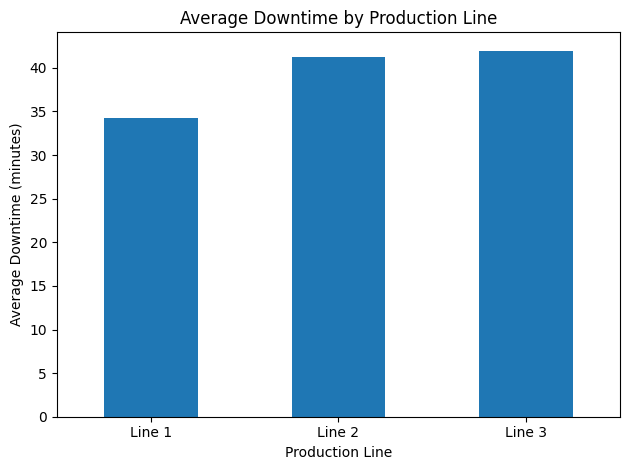

In [19]:
downtime_summary["Avg_Downtime"].plot(
    kind="bar",
    title="Average Downtime by Production Line",
    ylabel="Average Downtime (minutes)",
    xlabel="Production Line"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
downtime_variation = df.groupby("Line")["Downtime_min"].agg(
    ["mean", "median", "std", "min", "max"]
)

print(downtime_variation.round(2))

         mean  median    std  min   max
Line                                   
Line 1  34.21   32.80  11.84  7.1  67.7
Line 2  41.29   40.85  14.70  4.0  80.6
Line 3  41.98   44.70  15.13  7.3  72.6


In [21]:
df[df["Line"].isin(["Line 2", "Line 3"])].groupby(
    ["Line", "Shift"]
)["Downtime_min"].agg(["mean", "median", "count"]).round(2)

mean  median  count
Line   Shift                      
Line 2 A      32.09   32.85     18
       B      44.49   47.50     23
       C      46.72   44.90     17
Line 3 A      37.98   41.90     16
       B      42.12   43.50     15
       C      46.39   45.55     14

In [22]:
shift_output = df[df["Line"].isin(["Line 2", "Line 3"])].groupby(
    ["Line", "Shift"]
).agg(
    Planned_Units=("Planned_Units", "sum"),
    Actual_Units=("Actual_Units", "sum"),
    Avg_Downtime=("Downtime_min", "mean")
)

shift_output["Output_Achievement_pct"] = (
    shift_output["Actual_Units"] /
    shift_output["Planned_Units"] * 100
).round(2)

print(shift_output.round(2))

              Planned_Units  Actual_Units  Avg_Downtime  \
Line   Shift                                              
Line 2 A               9059          8211         32.09   
       B              11597         10234         44.49   
       C               8668          7661         46.72   
Line 3 A               8392          7574         37.98   
       B               7769          6848         42.12   
       C               7004          6177         46.39   

              Output_Achievement_pct  
Line   Shift                          
Line 2 A                       90.64  
       B                       88.25  
       C                       88.38  
Line 3 A                       90.25  
       B                       88.15  
       C                       88.19  


In [23]:
df[df["Line"].isin(["Line 2", "Line 3"])].groupby(
    ["Line", "Shift"]
).agg(
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Downtime=("Downtime_min", "mean")
).round(2)

Avg_Material_Wait  Avg_Cycle_Time  Avg_Downtime
Line   Shift                                                 
Line 2 A                  16.54           26.96         32.09
       B                  15.90           28.51         44.49
       C                  14.62           30.71         46.72
Line 3 A                  18.67           28.72         37.98
       B                  19.71           31.73         42.12
       C                  16.32           32.10         46.39

In [24]:
print(
    "Downtime vs Output Achievement:",
    round(df["Downtime_min"].corr(df["Output_Achievement_pct"]), 3)
)

Downtime vs Output Achievement: -0.772


In [25]:
for line, group in df.groupby("Line"):
    corr = group["Downtime_min"].corr(
        group["Output_Achievement_pct"]
    )
    print(line, round(corr, 3))

Line 1 -0.751
Line 2 -0.743
Line 3 -0.79


In [26]:
machine_summary = df[df["Line"] == "Line 3"].groupby("Machine").agg(
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean")
)

print(machine_summary.round(2))

             Avg_Downtime  Avg_Cycle_Time  Avg_Material_Wait
Machine                                                     
Assembly-01         41.79           32.23              18.47
CNC-01              39.55           30.76              15.12
CNC-02              43.99           29.49              20.54


In [27]:
df.groupby(["Line", "Machine"]).agg(
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean")
).round(2)

Avg_Downtime  Avg_Material_Wait  Avg_Cycle_Time
Line   Machine                                                     
Line 1 Assembly-01         32.45              11.50           27.31
       CNC-01              34.25              13.43           29.16
       CNC-02              36.24              12.90           28.43
Line 2 Assembly-01         38.90              16.76           28.71
       CNC-01              40.79              16.09           29.21
       CNC-02              44.24              14.32           28.18
Line 3 Assembly-01         41.79              18.47           32.23
       CNC-01              39.55              15.12           30.76
       CNC-02              43.99              20.54           29.49

In [28]:
df.groupby(["Line", "Machine"]).agg(
    Avg_Output_Achievement=("Output_Achievement_pct", "mean"),
    Avg_Downtime=("Downtime_min", "mean")
).round(2)

Avg_Output_Achievement  Avg_Downtime
Line   Machine                                          
Line 1 Assembly-01                   91.25         32.45
       CNC-01                        90.06         34.25
       CNC-02                        90.30         36.24
Line 2 Assembly-01                   88.83         38.90
       CNC-01                        90.01         40.79
       CNC-02                        88.29         44.24
Line 3 Assembly-01                   89.46         41.79
       CNC-01                        88.42         39.55
       CNC-02                        88.64         43.99

In [29]:
df.groupby(["Line", "Machine"]).agg(
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean")
).round(2)

Avg_Cycle_Time  Avg_Output_Achievement
Line   Machine                                            
Line 1 Assembly-01           27.31                   91.25
       CNC-01                29.16                   90.06
       CNC-02                28.43                   90.30
Line 2 Assembly-01           28.71                   88.83
       CNC-01                29.21                   90.01
       CNC-02                28.18                   88.29
Line 3 Assembly-01           32.23                   89.46
       CNC-01                30.76                   88.42
       CNC-02                29.49                   88.64

In [30]:
machine_analysis = df.groupby(["Line", "Machine"]).agg(
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean")
).round(2)

print(machine_analysis)

                    Avg_Downtime  Avg_Material_Wait  Avg_Cycle_Time  \
Line   Machine                                                        
Line 1 Assembly-01         32.45              11.50           27.31   
       CNC-01              34.25              13.43           29.16   
       CNC-02              36.24              12.90           28.43   
Line 2 Assembly-01         38.90              16.76           28.71   
       CNC-01              40.79              16.09           29.21   
       CNC-02              44.24              14.32           28.18   
Line 3 Assembly-01         41.79              18.47           32.23   
       CNC-01              39.55              15.12           30.76   
       CNC-02              43.99              20.54           29.49   

                    Avg_Output_Achievement  
Line   Machine                              
Line 1 Assembly-01                   91.25  
       CNC-01                        90.06  
       CNC-02                        9

In [31]:
df[
    ((df["Line"] == "Line 2") & (df["Machine"] == "CNC-02")) |
    ((df["Line"] == "Line 3") & (df["Machine"] == "CNC-02"))
].groupby(["Line", "Machine"]).agg(
    Records=("Date", "count"),
    Avg_Downtime=("Downtime_min", "mean"),
    Median_Downtime=("Downtime_min", "median"),
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean")
).round(2)

,,Records,Avg_Downtime,Median_Downtime,Avg_Material_Wait,Avg_Output_Achievement
Line,Machine,,,,,
Line 2,CNC-02,20,44.24,47.65,14.32,88.29
Line 3,CNC-02,17,43.99,43.80,20.54,88.64


In [32]:
df.groupby(["Line", "Machine"])["Downtime_min"].agg(
    ["mean", "median", "std", "min", "max"]
).round(2)

mean  median    std   min   max
Line   Machine                                      
Line 1 Assembly-01  32.45   32.20  11.56   7.1  53.7
       CNC-01       34.25   31.90  13.60  12.2  67.7
       CNC-02       36.24   36.00   9.99  14.3  58.3
Line 2 Assembly-01  38.90   38.60  13.82   4.0  65.4
       CNC-01       40.79   37.60  13.43  12.3  63.2
       CNC-02       44.24   47.65  16.72  17.0  80.6
Line 3 Assembly-01  41.79   44.70  17.37  11.4  72.6
       CNC-01       39.55   47.00  17.56   7.3  61.8
       CNC-02       43.99   43.80  11.19  23.9  65.1

In [33]:
df["Downtime_Level"] = pd.cut(
    df["Downtime_min"],
    bins=[0, 30, 45, float("inf")],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

df.groupby("Downtime_Level", observed=True).agg(
    Records=("Output_Achievement_pct", "count"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean"),
    Avg_Downtime=("Downtime_min", "mean")
).round(2)

,Records,Avg_Output_Achievement,Avg_Downtime
Downtime_Level,,,
Low,45,92.90,20.92
Medium,77,89.83,36.68
High,58,86.80,54.36


In [34]:
df[df["Downtime_Level"] == "High"].groupby("Line").agg(
    High_Downtime_Records=("Downtime_min", "count"),
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean")
).round(2)

,High_Downtime_Records,Avg_Downtime,Avg_Output_Achievement
Line,,,
Line 1,12,52.98,86.40
Line 2,24,55.27,86.97
Line 3,22,54.13,86.83


In [35]:
high_downtime_summary = df.groupby("Line").agg(
    Total_Records=("Downtime_min", "count"),
    High_Downtime_Records=("Downtime_Level", lambda x: (x == "High").sum())
)

high_downtime_summary["High_Downtime_pct"] = (
    high_downtime_summary["High_Downtime_Records"]
    / high_downtime_summary["Total_Records"] * 100
).round(2)

print(high_downtime_summary)

        Total_Records  High_Downtime_Records  High_Downtime_pct
Line                                                           
Line 1             77                     12              15.58
Line 2             58                     24              41.38
Line 3             45                     22              48.89


In [36]:
line3 = df[df["Line"] == "Line 3"]

print(
    line3.groupby("Machine").agg(
        Records=("Downtime_Level", "count"),
        High_Downtime_Records=(
            "Downtime_Level",
            lambda x: (x == "High").sum()
        ),
        Avg_Downtime=("Downtime_min", "mean"),
        Avg_Material_Wait=("Material_Wait_min", "mean"),
        Avg_Output_Achievement=("Output_Achievement_pct", "mean")
    ).round(2)
)

             Records  High_Downtime_Records  Avg_Downtime  Avg_Material_Wait  \
Machine                                                                        
Assembly-01       15                      7         41.79              18.47   
CNC-01            13                      7         39.55              15.12   
CNC-02            17                      8         43.99              20.54   

             Avg_Output_Achievement  
Machine                              
Assembly-01                   89.46  
CNC-01                        88.42  
CNC-02                        88.64  


In [37]:
line3.groupby("Machine")[[
    "Material_Wait_min",
    "Downtime_min",
    "Output_Achievement_pct"
]].corr().round(2)

Material_Wait_min  Downtime_min  \
Machine                                                               
Assembly-01 Material_Wait_min                    1.00         -0.43   
            Downtime_min                        -0.43          1.00   
            Output_Achievement_pct               0.40         -0.90   
CNC-01      Material_Wait_min                    1.00         -0.38   
            Downtime_min                        -0.38          1.00   
            Output_Achievement_pct               0.44         -0.80   
CNC-02      Material_Wait_min                    1.00          0.09   
            Downtime_min                         0.09          1.00   
            Output_Achievement_pct               0.10         -0.66   

                                    Output_Achievement_pct  
Machine                                                     
Assembly-01 Material_Wait_min                         0.40  
            Downtime_min                             -0.90  
            Output_Achievement_pct                    1.00  
CNC-01      Material_Wait_min                         0.44  
            Downtime_min                             -0.80  
            Output_Achievement_pct                    1.00  
CNC-02      Material_Wait_min                         0.10  
            Downtime_min                             -0.66  
            Output_Achievement_pct                    1.00

In [38]:
# Filter Line 3
line3 = df[df["Line"] == "Line 3"]

# Compare downtime and output by machine and shift
line3.groupby(["Machine", "Shift"]).agg(
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean"),
    Records=("Downtime_min", "count")
).round(2)

Avg_Downtime  Avg_Output_Achievement  Records
Machine     Shift                                               
Assembly-01 A             41.33                   90.52        3
            B             27.92                   91.42        4
            C             48.90                   88.08        8
CNC-01      A             35.64                   89.69        8
            B             43.70                   86.32        2
            C             47.20                   86.46        3
CNC-02      A             39.72                   90.56        5
            B             48.08                   86.92        9
            C             38.87                   90.60        3

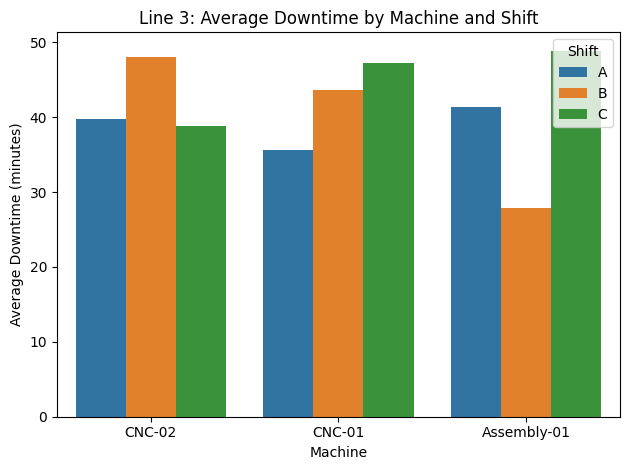

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(
    data=line3,
    x="Machine",
    y="Downtime_min",
    hue="Shift",
    errorbar=None
)

plt.title("Line 3: Average Downtime by Machine and Shift")
plt.ylabel("Average Downtime (minutes)")
plt.tight_layout()
plt.show()

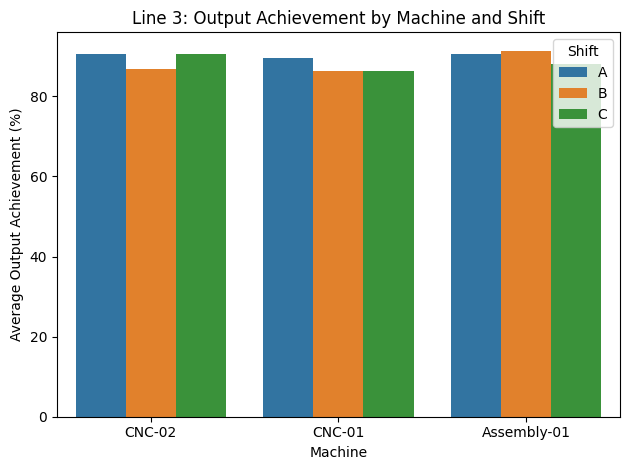

In [40]:
sns.barplot(
    data=line3,
    x="Machine",
    y="Output_Achievement_pct",
    hue="Shift",
    errorbar=None
)

plt.title("Line 3: Output Achievement by Machine and Shift")
plt.ylabel("Average Output Achievement (%)")
plt.tight_layout()
plt.show()

In [41]:
shift_b = line3[
    (line3["Machine"] == "CNC-01") &
    (line3["Shift"] == "B")
]

print(shift_b[[
    "Date",
    "Downtime_min",
    "Output_Achievement_pct",
    "Material_Wait_min",
    "Cycle_Time_sec_per_unit"
]])

         Date  Downtime_min  Output_Achievement_pct  Material_Wait_min  \
63 2026-07-10          27.4                   90.55                7.3   
71 2026-07-11          60.0                   82.09               24.4   

    Cycle_Time_sec_per_unit  
63                     28.3  
71                     37.0  


In [42]:
line3.groupby(
    pd.cut(
        line3["Downtime_min"],
        bins=[0, 30, 45, float("inf")],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )
).agg(
    Records=("Output_Achievement_pct", "count"),
    Avg_Output=("Output_Achievement_pct", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean")
).round(2)

/tmp/ipykernel_1575/3220523001.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  line3.groupby(


,Records,Avg_Output,Avg_Cycle_Time,Avg_Material_Wait
Downtime_min,,,,
Low,11,92.63,30.23,20.71
Medium,12,89.09,30.33,17.53
High,22,86.83,31.29,17.49


In [43]:
line3 = df[df["Line"] == "Line 3"].copy()

baseline_output = line3["Actual_Units"].sum()

# Hypothetical 10% downtime reduction
reduced_downtime = line3["Downtime_min"] * 0.90

print("Current total output:", baseline_output)
print("Current total downtime:", round(line3["Downtime_min"].sum(), 2))
print("Downtime after hypothetical 10% reduction:",
      round(reduced_downtime.sum(), 2))

Current total output: 20599
Current total downtime: 1888.9
Downtime after hypothetical 10% reduction: 1700.01


In [44]:
line_summary = df.groupby("Line").agg(
    Planned_Units=("Planned_Units", "sum"),
    Actual_Units=("Actual_Units", "sum"),
    Total_Downtime=("Downtime_min", "sum"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean")
).round(2)

line_summary["Output_Achievement_pct"] = (
    line_summary["Actual_Units"]
    / line_summary["Planned_Units"] * 100
).round(2)

print(line_summary)

        Planned_Units  Actual_Units  Total_Downtime  Avg_Cycle_Time  \
Line                                                                  
Line 1          38402         34812          2634.5           28.30   
Line 2          29324         26106          2395.1           28.67   
Line 3          23165         20599          1888.9           30.77   

        Avg_Material_Wait  Output_Achievement_pct  
Line                                               
Line 1              12.59                   90.65  
Line 2              15.72                   89.03  
Line 3              18.28                   88.92  


In [47]:
machine_summary = df.groupby(["Line", "Machine"]).agg(
    Avg_Downtime=("Downtime_min", "mean"),
    Avg_Material_Wait=("Material_Wait_min", "mean"),
    Avg_Cycle_Time=("Cycle_Time_sec_per_unit", "mean"),
    Avg_Output_Achievement=("Output_Achievement_pct", "mean")
).round(2)

df[["Line", "Machine"]].drop_duplicates().sort_values(["Line", "Machine"])

machine_summary.to_csv("machine_performance_summary.csv", index=False)

from google.colab import files
files.download("machine_performance_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Line,Machine
1,Line 1,Assembly-01
21,Line 1,CNC-01
0,Line 1,CNC-02
7,Line 2,Assembly-01
28,Line 2,CNC-01
4,Line 2,CNC-02
15,Line 3,Assembly-01
9,Line 3,CNC-01
5,Line 3,CNC-02
